# Lecture 2 — Class Exercise
# Bar Charts: World Happiness Report 2023

---

> **Your task:** Create **2 polished bar charts** using the World Happiness Report dataset.  
> **Push to:** `week02/lecture02_exercise.ipynb` in **your own GitHub repo** before the end of class.

---

### Rules to keep in mind 💡
1. Every bar chart **must have a zero baseline** — no exceptions
2. Every chart **must have an insight title**, not a topic title
3. Aim for **professional quality** — clean background, readable font, no clutter
4. Horizontal bars for long category names

---


## Setup — Run this cell first


In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go

df = pd.read_csv('../data/world_happiness_2023.csv')

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head()) 

Dataset shape: (63, 9)
Columns: ['Country name', 'Regional indicator', 'Ladder score', 'Logged GDP per capita', 'Social support', 'Healthy life expectancy', 'Freedom to make life choices', 'Generosity', 'Perceptions of corruption']
  Country name            Regional indicator  Ladder score  \
0      Finland                Western Europe         7.804   
1      Denmark                Western Europe         7.586   
2      Iceland                Western Europe         7.525   
3       Israel  Middle East and North Africa         7.473   
4  Netherlands                Western Europe         7.464   

   Logged GDP per capita  Social support  Healthy life expectancy  \
0                 10.775           0.954                     71.9   
1                 10.933           0.954                     72.7   
2                 10.878           0.983                     72.5   
3                 10.527           0.916                     72.4   
4                 11.015           0.939          

In [2]:
%pip install plotly

Note: you may need to restart the kernel to use updated packages.


In [3]:
df = df.rename(columns={
    'Country name': 'Country',
    'Regional indicator': 'Region',
    'Ladder score': 'Happiness_Score',
    'Logged GDP per capita': 'GDP',
    'Social support': 'Social_Support',
    'Healthy life expectancy': 'Life_Expectancy',
    'Freedom to make life choices': 'Freedom',
    'Generosity': 'Generosity',
    'Perceptions of corruption': 'Corruption'
})

print(df.columns.tolist())


['Country', 'Region', 'Happiness_Score', 'GDP', 'Social_Support', 'Life_Expectancy', 'Freedom', 'Generosity', 'Corruption']


In [4]:
import plotly.express as px
import plotly.graph_objects as go

# Explore the dataset before you start
print("Regions in dataset:")
print(df['Region'].value_counts())
print("\nScore range:", df['Happiness_Score'].min(), "–", df['Happiness_Score'].max())
print("\nBottom 10 countries:")
print(df.nsmallest(10, 'Happiness_Score')[['Country','Region','Happiness_Score']])


Regions in dataset:
Region
Western Europe                  15
Latin America and Caribbean     13
Central and Eastern Europe       7
Sub-Saharan Africa               7
Middle East and North Africa     6
North America and ANZ            4
Southeast Asia                   4
South Asia                       4
East Asia                        3
Name: count, dtype: int64

Score range: 1.859 – 7.804

Bottom 10 countries:
        Country                        Region  Happiness_Score
60  Afghanistan                    South Asia            1.859
61      Lebanon  Middle East and North Africa            2.392
62     Zimbabwe            Sub-Saharan Africa            2.995
52     Ethiopia            Sub-Saharan Africa            3.564
53     Tanzania            Sub-Saharan Africa            3.698
48   Bangladesh                    South Asia            3.892
47        India                    South Asia            4.036
50        Kenya            Sub-Saharan Africa            4.112
54       Uganda

---
## Task 1 — Regional Comparison Bar Chart

**What to build:** A horizontal bar chart showing the **average happiness score by region**, sorted from highest to lowest.

**Requirements:**
- Horizontal orientation (category names are long)
- Sorted by score, descending (so the happiest region is at the top)
- Zero baseline on x-axis
- At least one design choice that goes beyond the Plotly default (colour, annotation, labels, etc.)
- An insight title that answers: *which region stands out and why does it matter?*

**Hint:** Use `df.groupby('Region')['Happiness_Score'].mean()` to compute the averages.


                         Region  Happiness_Score
8                Western Europe         7.085533
4         North America and ANZ         7.018250
0    Central and Eastern Europe         6.338143
1                     East Asia         5.966000
2   Latin America and Caribbean         5.699000
6                Southeast Asia         5.695250
3  Middle East and North Africa         4.943333
7            Sub-Saharan Africa         4.064714
5                    South Asia         3.618250


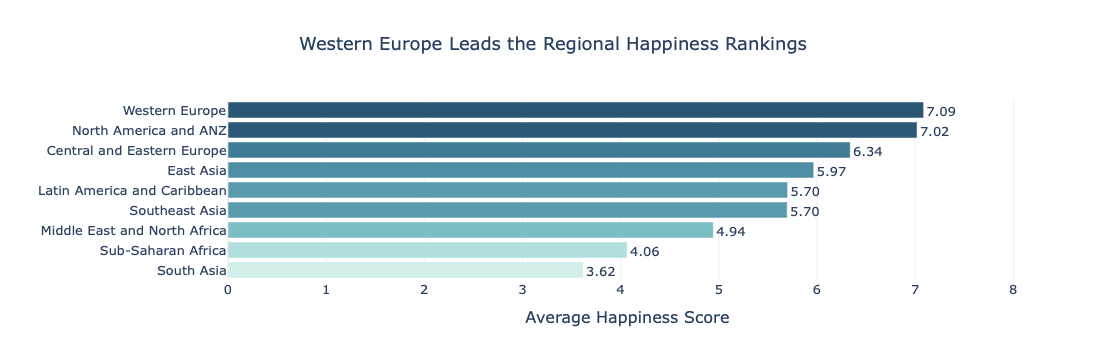

In [5]:
# Task 1: Regional Comparison Bar Chart

# Step 1: Calculate average happiness score for each region
region_avg = (
    df.groupby('Region')['Happiness_Score']
    .mean()
    .reset_index()
    .sort_values('Happiness_Score', ascending=False)
)

print(region_avg)

# Step 2: Create the horizontal bar chart
fig1 = px.bar(
    region_avg,
    x='Happiness_Score',
    y='Region',
    orientation='h',
    title='Western Europe Leads the Regional Happiness Rankings',
    labels={
        'Happiness_Score': 'Average Happiness Score',
        'Region': 'Region'
    },
    text_auto='.2f',
    color='Happiness_Score',
    color_continuous_scale='Teal'
)

# Keep the happiness axis starting at zero
fig1.update_layout(
    template='plotly_white',
    xaxis=dict(
        range=[0, region_avg['Happiness_Score'].max() * 1.15],
        title='Average Happiness Score'
    ),
    yaxis=dict(
        title='',
        autorange='reversed'
    ),
    title_x=0.5,
    font=dict(size=13),
    coloraxis_showscale=False
)

fig1.update_traces(textposition='outside')
fig1.show()




---
## Task 2 — Bottom vs. Top: A Contrast Story

**What to build:** A bar chart that highlights the **gap between the happiest and least happy countries**, focusing on a specific insight.

**Requirements:**
- Show the **top 8 AND bottom 8 countries** together (16 bars total)
- Use **colour** to distinguish the two groups (not Plotly's default rainbow)
- Add a **visual separator or annotation** that emphasises the gap
- Insight title that tells the story of the gap

**Hint:** Use `pd.concat([df.nlargest(8,'Happiness_Score'), df.nsmallest(8,'Happiness_Score')])` to get both groups.

**Stretch goal:** Add a vertical reference line showing the global average.


Global average happiness score: 5.81


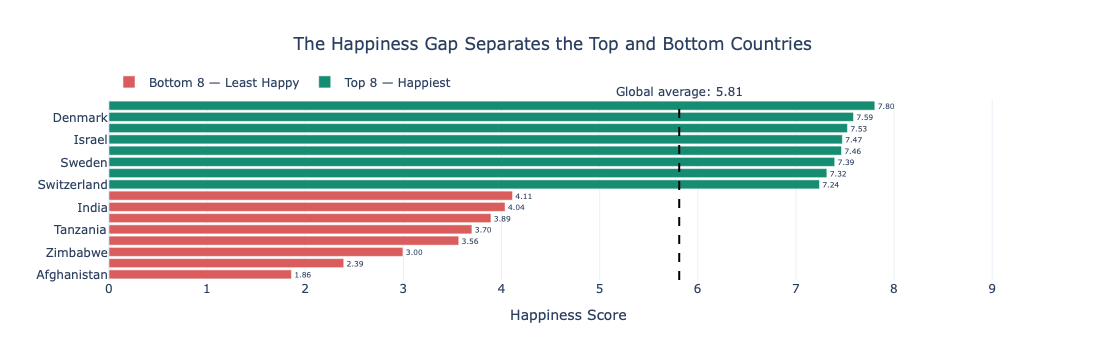

In [6]:

# Task 2: Top 8 vs Bottom 8 Countries

# Step 1: Select the happiest and least happy countries
top8 = df.nlargest(8, 'Happiness_Score').copy()
top8['Group'] = 'Top 8 — Happiest'

bottom8 = df.nsmallest(8, 'Happiness_Score').copy()
bottom8['Group'] = 'Bottom 8 — Least Happy'

combined = pd.concat([bottom8, top8]).sort_values(
    'Happiness_Score',
    ascending=True
)

global_avg = df['Happiness_Score'].mean()

print(f"Global average happiness score: {global_avg:.2f}")

# Step 2: Create the chart
fig2 = px.bar(
    combined,
    x='Happiness_Score',
    y='Country',
    orientation='h',
    color='Group',
    color_discrete_map={
        'Top 8 — Happiest': '#168C72',
        'Bottom 8 — Least Happy': '#D95D5D'
    },
    title='The Happiness Gap Separates the Top and Bottom Countries',
    labels={
        'Happiness_Score': 'Happiness Score',
        'Country': 'Country',
        'Group': 'Country Group'
    },
    text='Happiness_Score'
)

fig2.update_layout(
    template='plotly_white',
    xaxis=dict(
        range=[0, combined['Happiness_Score'].max() * 1.2],
        title='Happiness Score'
    ),
    yaxis=dict(title=''),
    title_x=0.5,
    font=dict(size=12),
    legend_title_text='',
    legend=dict(orientation='h', yanchor='bottom', y=1.02)
)

fig2.update_traces(texttemplate='%{text:.2f}', textposition='outside')

# Mark the global average
fig2.add_vline(
    x=global_avg,
    line_dash='dash',
    line_color='black',
    annotation_text=f'Global average: {global_avg:.2f}',
    annotation_position='top'
)

fig2.show()


---
## Done? Stretch Goal

If you finish both tasks with time to spare, try this:

**Task 3 (stretch):** Build a **grouped bar chart** comparing 2 sub-factors (e.g. `GDP_per_capita` and `Freedom`) across the 5 most populated regions. Use colour meaningfully and write an insight title.

Regions to include: `'Western Europe'`, `'Latin America'`, `'East Asia'`, `'Sub-Saharan Africa'`, `'South Asia'`


               Region        GDP   Freedom
0      Western Europe  10.963533  0.896067
1       Latin America        NaN       NaN
2           East Asia  10.312000  0.754000
3  Sub-Saharan Africa   7.082000  0.599429
4          South Asia   7.152250  0.546250


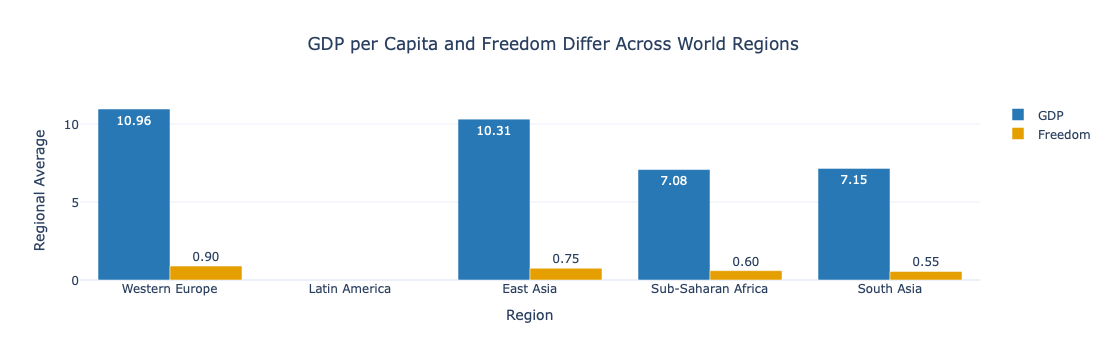

In [7]:
# Stretch goal — grouped bar chart
# YOUR CODE HERE

# Task 3: GDP and Freedom across five regions

# Step 1: Select the five required regions
selected_regions = [
    'Western Europe',
    'Latin America',
    'East Asia',
    'Sub-Saharan Africa',
    'South Asia'
]

# Step 2: Filter the dataset and calculate regional averages
region_factors = (
    df[df['Region'].isin(selected_regions)]
    .groupby('Region')[['GDP', 'Freedom']]
    .mean()
    .reindex(selected_regions)
    .reset_index()
)

print(region_factors)

# Step 3: Reshape the data for a grouped bar chart
chart_data = region_factors.melt(
    id_vars='Region',
    value_vars=['GDP', 'Freedom'],
    var_name='Factor',
    value_name='Average Value'
)

# Step 4: Create the grouped bar chart
fig3 = px.bar(
    chart_data,
    x='Region',
    y='Average Value',
    color='Factor',
    barmode='group',
    color_discrete_map={
        'GDP': '#2878B5',
        'Freedom': '#E69F00'
    },
    title='GDP per Capita and Freedom Differ Across World Regions',
    labels={
        'Region': 'Region',
        'Average Value': 'Regional Average',
        'Factor': 'Indicator'
    },
    text_auto='.2f'
)

fig3.update_layout(
    template='plotly_white',
    yaxis=dict(rangemode='tozero', title='Regional Average'),
    xaxis_title='Region',
    title_x=0.5,
    font=dict(size=12),
    legend_title_text=''
)

fig3.show()


